In [92]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [93]:
df=pd.read_csv("house_price_multiple_regression_100.csv")
df.head()

,House_Size_sqft,Bedrooms,House_Age_years,Distance_to_City_km,Price_Lakh
0,1959,3,23,6.8,105.8
1,2035,4,17,2.8,133.9
2,1514,2,2,5.6,91.0
3,1057,2,22,12.4,46.1
4,1101,2,8,18.0,66.1


In [94]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   House_Size_sqft       100 non-null    int64  
 1    Bedrooms             100 non-null    int64  
 2    House_Age_years      100 non-null    int64  
 3    Distance_to_City_km  100 non-null    float64
 4    Price_Lakh           100 non-null    float64
dtypes: float64(2), int64(3)
memory usage: 4.0 KB


In [95]:
df.isnull().sum()

House_Size_sqft         0
 Bedrooms               0
 House_Age_years        0
 Distance_to_City_km    0
 Price_Lakh             0
dtype: int64

In [96]:
df.describe()

,House_Size_sqft,Bedrooms,House_Age_years,Distance_to_City_km,Price_Lakh
count,100.000000,100.000000,100.000000,100.000000,100.000000
mean,1615.150000,3.000000,14.410000,11.444000,88.046000
std,572.508839,1.110101,9.096669,5.761617,37.683805
min,650.000000,1.000000,0.000000,1.100000,18.000000
25%,1099.500000,2.000000,7.000000,6.750000,57.100000
50%,1680.000000,3.000000,14.000000,10.650000,89.000000
75%,2060.500000,4.000000,21.250000,16.600000,119.125000
max,2578.000000,5.000000,30.000000,21.700000,172.100000


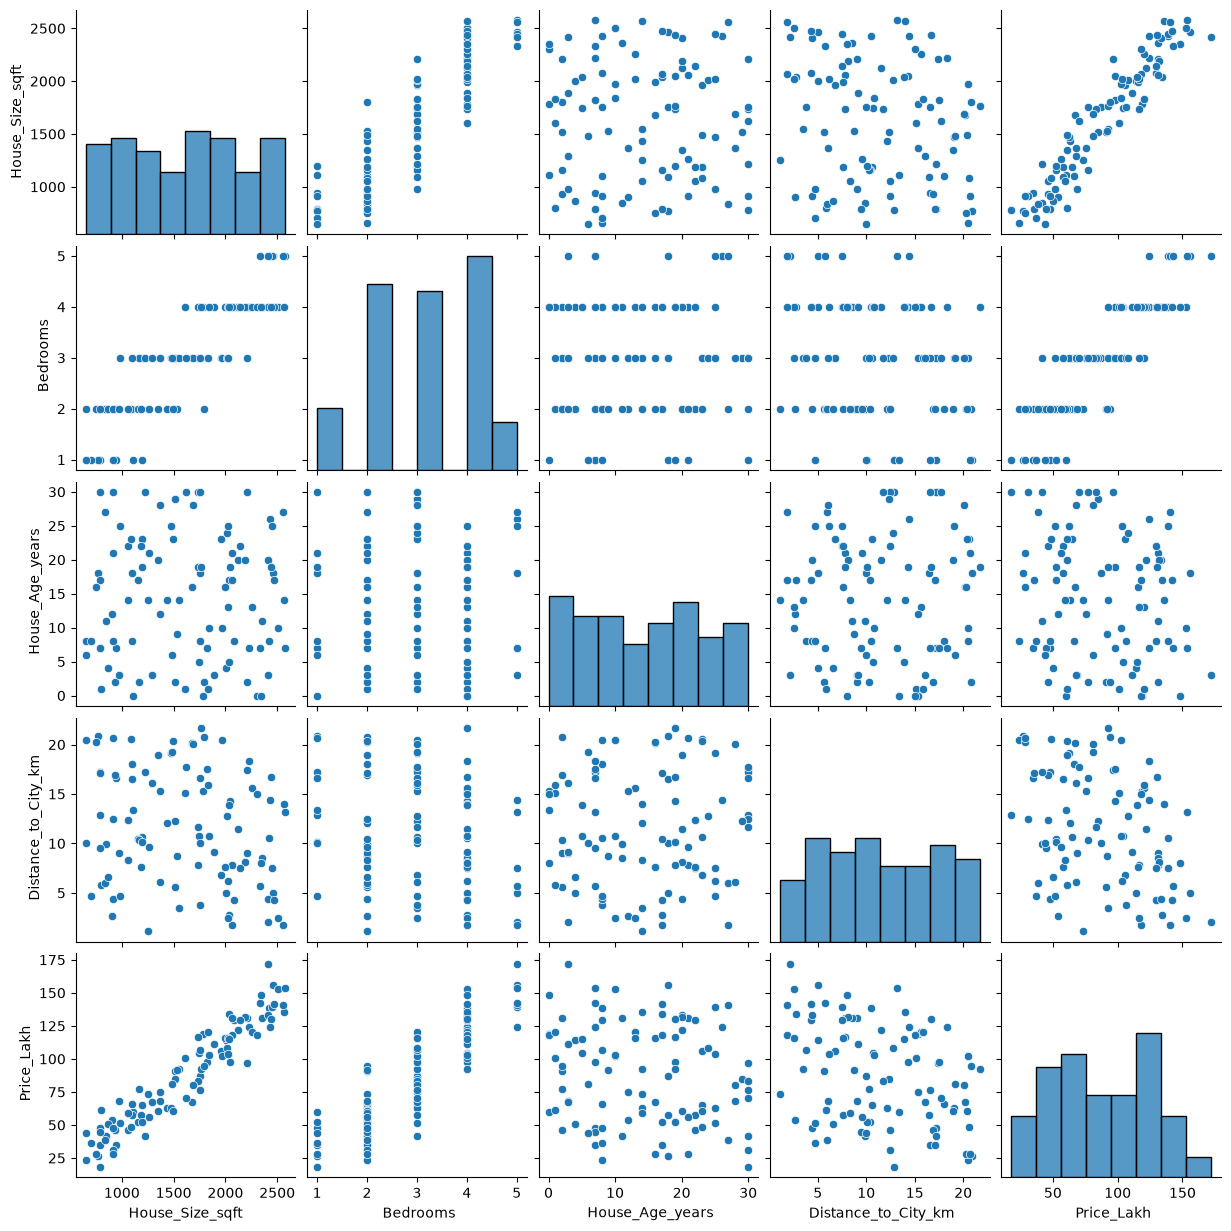

In [97]:
sns.pairplot(df)

In [98]:
#Correlation 
df.corr()

,House_Size_sqft,Bedrooms,House_Age_years,Distance_to_City_km,Price_Lakh
House_Size_sqft,1.000000,0.876560,0.016594,-0.210796,0.950673
Bedrooms,0.876560,1.000000,0.009002,-0.254579,0.884014
House_Age_years,0.016594,0.009002,1.000000,0.064678,-0.167042
Distance_to_City_km,-0.210796,-0.254579,0.064678,1.000000,-0.360904
Price_Lakh,0.950673,0.884014,-0.167042,-0.360904,1.000000


<Axes: >

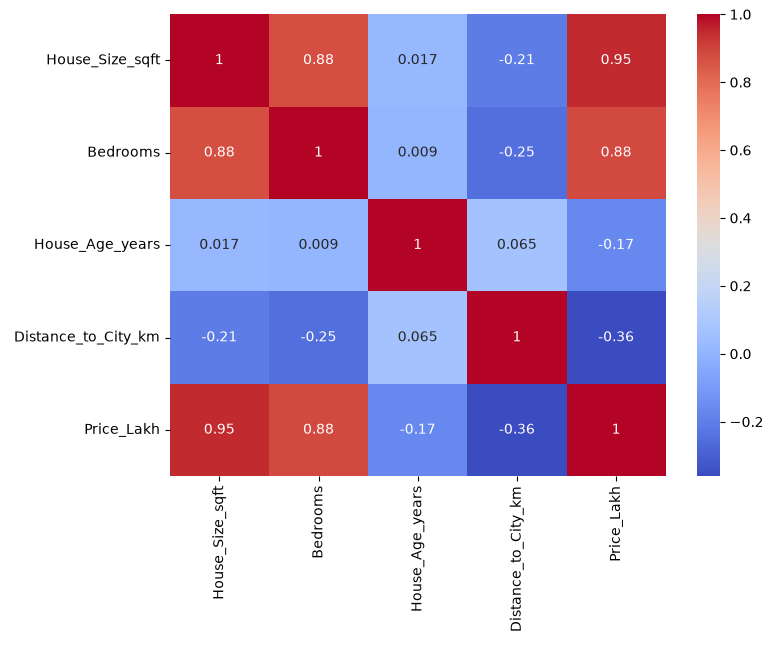

In [99]:
#Heat Map
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(),annot=True,cmap="coolwarm")

Text(0, 0.5, 'Price(Laks)')

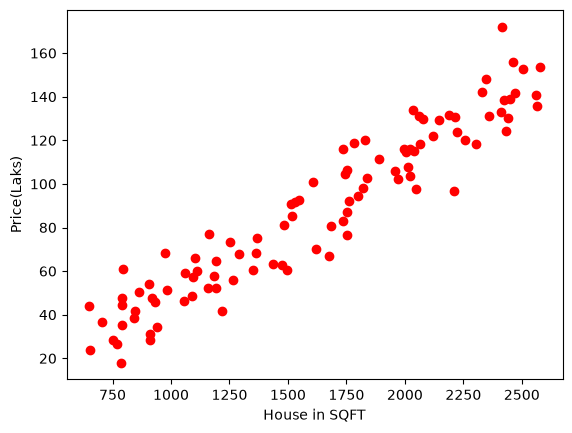

In [100]:
plt.scatter(df["House_Size_sqft"],df[" Price_Lakh"],color="r")
plt.xlabel("House in SQFT")
plt.ylabel("Price(Laks)")


<Axes: xlabel='House_Size_sqft', ylabel=' Price_Lakh'>

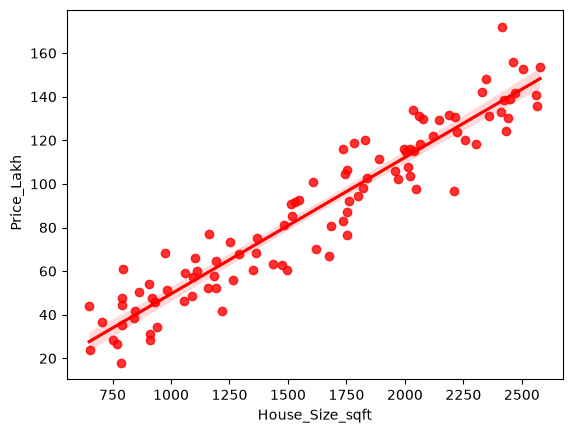

In [101]:
sns.regplot(x=df["House_Size_sqft"],y=df[" Price_Lakh"],color="r")

<Axes: xlabel=' Bedrooms', ylabel=' Price_Lakh'>

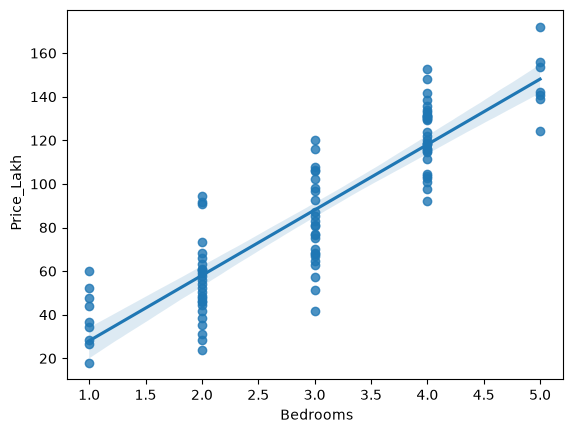

In [102]:
sns.regplot(x=df[" Bedrooms"],y=df[" Price_Lakh"])

In [103]:
#Independent and Dependent Features
X=df.iloc[:,:-1]#All rows and all columns except last one
y=df.iloc[:,-1]


In [104]:
from sklearn.model_selection import train_test_split


In [105]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=45)

In [106]:
print(X_train.shape)
print(X_test.shape)

(75, 4)
(25, 4)


In [107]:
#Standardize
from sklearn.preprocessing import StandardScaler
scalar=StandardScaler()

In [108]:
X_train=scalar.fit_transform(X_train)
X_test=scalar.transform(X_test)
X_train
X_test

array([[ 0.63429455, -0.01224072,  0.94904215, -0.90710964],
       [ 0.76769229,  0.90581314,  0.31067299, -1.65329251],
       [ 1.69972124,  0.90581314, -0.00851159,  0.43601952],
       [ 1.68918984,  1.82386701,  1.37462159, -1.83983823],
       [-0.08886162, -0.01224072, -0.00851159, -1.52271051],
       [ 0.03751519, -0.01224072,  1.69380617,  1.12623868],
       [ 1.48031706,  0.90581314,  0.52346271,  0.93969296],
       [-0.85589862, -1.84834844, -1.49803963,  0.32409209],
       [-0.14678432, -0.93029458, -1.28524991, -1.13096451],
       [ 1.28548615,  1.82386701, -0.75327561, -1.11230993],
       [-0.72601135, -0.93029458,  0.84264729, -0.75787307],
       [-0.60841071, -0.93029458, -0.00851159, -1.97042024],
       [-0.43113213, -0.93029458,  0.62985757,  1.35009354],
       [-1.41581809, -0.93029458,  0.31067299,  1.01431125],
       [-1.65628506, -0.93029458, -0.64688075,  1.64856669],
       [-0.87169572, -0.93029458, -0.64688075,  1.1822024 ],
       [ 0.74662949, -0.

In [109]:
from sklearn.linear_model import LinearRegression
regression=LinearRegression()

In [110]:
regression.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [111]:
#Cross Validation
from sklearn.model_selection import cross_val_score
validation_Score=cross_val_score(regression,X_train,y_train,scoring="neg_mean_squared_error",cv=5)
validation_Score

array([-78.18337741, -48.54591255, -24.50577452, -36.55527306,
       -88.72056694])

In [112]:
np.mean(validation_Score)

np.float64(-55.30218089532203)

In [113]:
print(X.columns)
print("Coefficient:",regression.coef_)
print("Intersept:",regression.intercept_)
for col_name,coef in zip(X.columns,regression.coef_):
    print(f"{col_name} :{coef}")

Index(['House_Size_sqft', ' Bedrooms', ' House_Age_years',
       ' Distance_to_City_km'],
      dtype='object')
Coefficient: [28.71719837  6.9733358  -6.41836614 -5.30033193]
Intersept: 86.88533333333334
House_Size_sqft :28.717198367368404
 Bedrooms :6.973335800157589
 House_Age_years :-6.418366135482556
 Distance_to_City_km :-5.300331928400851


In [114]:
y_pred=regression.predict(X_test)
y_pred

array([103.7318194 , 122.01683053, 139.75668689, 149.04149882,
        92.37361964,  71.03639882, 127.37197136,  57.31433955,
        90.42653414, 147.24974179,  58.15762487,  73.42473754,
        56.81856938,  32.36954871,  28.24817691,  53.25127019,
       118.03821895,  61.2632166 ,  32.74799247, 124.51774634,
        65.75776771, 147.13409331,  93.59870212, 115.65048312,
        89.71259967])

In [115]:
#Performance Metrices
from sklearn.metrics import mean_absolute_error,mean_squared_error
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
rmse=np.sqrt(mse)
print(mse)
print(mae)
print(rmse)

38.38258149795482
4.785776507474027
6.195367745175004


In [116]:
from sklearn.metrics import r2_score

In [117]:
score=r2_score(y_test,y_pred)
print(score)

0.9705923601151398


In [118]:
#Display Adjusted Rsquare 
print("R2         :",score)
print("Adjusted R2:",1-(1-score)*(len(y_test)-1)/(len(y_test)-X_test.shape[1]-1))

R2         : 0.9705923601151398
Adjusted R2: 0.9647108321381678


Text(0, 0.5, 'Predicted Price')

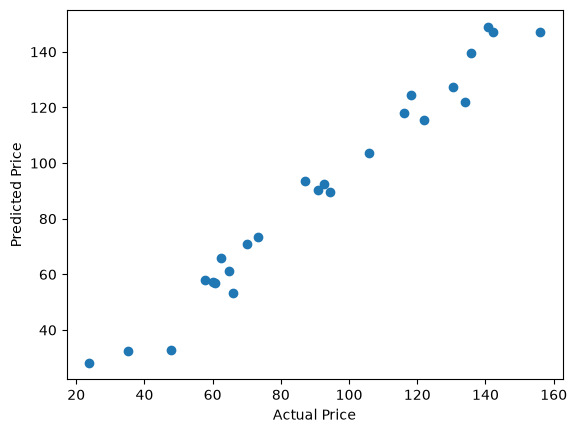

In [119]:
#Actuall vs predicted scatter
plt.scatter(y_test,y_pred)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

In [120]:
residuals=y_test-y_pred
residuals

0      2.068181
1     11.883169
62    -4.056687
76    -8.341499
37     0.226380
99    -0.836399
78     3.028029
38     2.685660
2      0.573466
84    -4.949742
60    -0.257625
26    -0.224738
69     3.781431
33     2.830451
51    -4.448177
4     12.848730
92    -1.938219
7      3.536783
10    15.052008
74    -6.417746
45    -3.157768
9      8.865907
20    -6.598702
18     6.449517
73     4.587400
Name:  Price_Lakh, dtype: float64

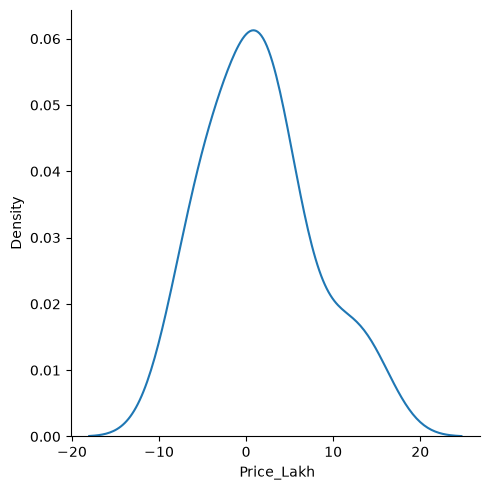

In [121]:
sns.displot(residuals,kind="kde")

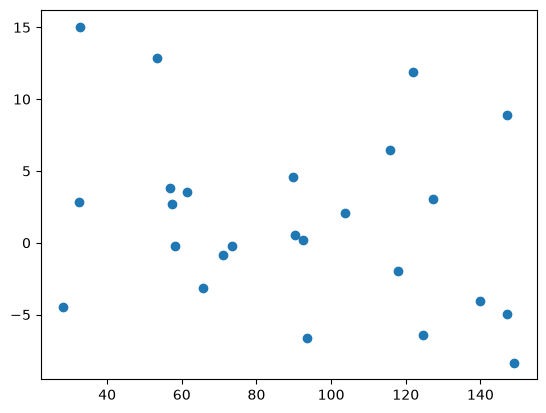

In [122]:
plt.scatter(y_pred,residuals)

In [123]:
import statsmodels.api as sm
model=sm.OLS(y_train,sm.add_constant(X_train)).fit()

In [124]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             Price_Lakh   R-squared:                       0.965
Model:                            OLS   Adj. R-squared:                  0.963
Method:                 Least Squares   F-statistic:                     485.3
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           3.16e-50
Time:                        11:39:31   Log-Likelihood:                -253.06
No. Observations:                  75   AIC:                             516.1
Df Residuals:                      70   BIC:                             527.7
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         86.8853      0.844    102.890      0.0

In [131]:
#Pesdiction
new_data=pd.DataFrame([[1191,3,23,10]],columns=X.columns)
regression.predict(scalar.transform(new_data))

array([61.85646913])